# Granovetter Threshold Model — Targeting for Maximum Spread

## 1. Setup

In [156]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import random
from time import time
import os
import multiprocessing as mp
from tqdm.auto import tqdm

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = False
plt.rcParams["figure.dpi"] = 120

print("Packages loaded (with multiprocessing and tqdm).")

Packages loaded (with multiprocessing and tqdm).


## 2. Configuration

In [157]:
# Parameters
#we derive N and k_avg from the Hamsterster network below
#B (number of initial adopters) is derived from f0 in the next cell

F0_VALUES = [0.01, 0.02, 0.05, 0.10]     # seed fractions for the f0-sweep (Step 3 f0 sweep)
F0_MAIN = 0.05                           # fixed seed fraction for strategy comparison (Step 3 tau sweep)
RUNS_PER_SETTING = 25                     # number of Monte Carlo simulation runs (20-50)

# Threshold mode, defines how the threshold is set for each node
THRESHOLD_MODE = 'beta'   # 'uniform', 'beta', 'constant', 'normal'
TAU_SWEEP = np.arange(0.05, 0.51, 0.05)  # tau values 0.05 ... 0.50 for the tau-sweep
TAU_MAIN = 0.20                          # fixed intermediate tau for f0-sweep
PHI_MEAN = 0.30
PHI_STD = 0.10

# Maximum number of steps in each simulation run
MAX_STEPS = 200                         #t_max 

print(f"f0 values: {F0_VALUES}, main f0: {F0_MAIN}, runs per setting: {RUNS_PER_SETTING}")

f0 values: [0.01, 0.02, 0.05, 0.1], main f0: 0.05, runs per setting: 25


## 3. Network

In [158]:
# Load the Hamsterster network 
FILEPATH = "datasets/petster-hamster.edges"
df = pd.read_csv(FILEPATH, comment="%", header=None,names=["source_profile", "dest_profile"])
df = df[df["source_profile"] != df["dest_profile"]]
G_full = nx.from_pandas_edgelist(df, "source_profile", "dest_profile")      #graph of full network (2426 nodes)
largest_cc = max(nx.connected_components(G_full), key=len)              
G = G_full.subgraph(largest_cc).copy()                                      #graph of LCC (2000 nodes)

# Structural dimensions LCC Hamsterster network
N = G.number_of_nodes()
M = G.number_of_edges()
k_avg = 2 * M / N
B_MAIN = int(round(F0_MAIN * N))   
print(f"LCC: N={N}, M={M}, <k>={k_avg:.2f}")

LCC: N=2000, M=16098, <k>=16.10


## 4. Threshold Distributions

In [159]:
def draw_thresholds(G, mode='uniform', tau=0.3, phi_mean=0.3, phi_std=0.1):
    """
        This function draws threshold values for each node in the graph G.
        The threshold mode determines how the threshold values are generated.
        Each node samples a threshold value from a specified distribution (defined by mode).
        The phi_mean and phi_std parameters are used to control the mean and standard deviation of the normal distribution.
    """
    if mode == 'uniform':
        return {n: np.random.uniform(0, 1) for n in G}
    if mode == 'beta':
        a, b = 2, 5
        return {n: np.random.beta(a, b) for n in G}
    if mode == 'constant':
        return {n: float(tau) for n in G}
    if mode == 'normal':
        vals = np.clip(np.random.normal(phi_mean, phi_std, len(G)), 0, 1)
        return {n: float(vals[i]) for i, n in enumerate(G)}
    raise ValueError(f"Unknown threshold mode: {mode}")

## 5. Threshold Dynamics

In [160]:
def threshold_dynamics(G, seeds, thresholds, max_steps=100):
    """
        This function simulates the threshold dynamics on a graph G
        The function takes as input the graph G, a list of seed nodes (seeds), a dictionary of threshold values (thresholds), and the maximum number of steps (max_steps)
        The function returns a dictionary of adopted nodes (adopted) and a numpy array of the fraction of adopted nodes over time (history)
    """
    adopted = {n: 0 for n in G}
    for s in seeds:
        adopted[s] = 1 # initially, all seed nodes are adopted

    history = [sum(adopted.values()) / len(G)] #the history will store the fraction of adopted nodes over time, initially it is the fraction of adopted seed nodes

    for _ in range(max_steps): # iterate max_steps times
        new_adopted = adopted.copy()
        changed = False
        for i in G: # iterate over all nodes i in the graph G
            if adopted[i] == 0: # if node i is not adopted yet
                neigh = list(G.neighbors(i))
                if not neigh: # if node i has no neighbors, skip it
                    continue
                frac = sum(adopted[j] for j in neigh) / len(neigh) # calculate the fraction of adopted neighbors of node i
                if frac >= thresholds[i]: # if the fraction of adopted neighbors is greater than or equal to the threshold of node i
                    new_adopted[i] = 1 # adopt node i
                    changed = True
        #-- end of one iteration

        # update the adopted nodes after checking all nodes
        adopted = new_adopted
        history.append(sum(adopted.values()) / len(G)) #add the total adopted this timestep to the history
        if not changed:
            break # if no node is adopted in this iteration, break the loop (no more adoptions so we can stop)

    return adopted, np.array(history)

## 6. Measurement Utilities

In [161]:
def final_adoption_fraction(adopted):
    """Steady-state cascade size S_infinity."""
    return sum(adopted.values()) / len(adopted)

# function to calculate the time to reach a target fraction of adopted nodes
def time_to_fraction(history, target=0.5):
    """First time step at which adoption fraction reaches target."""
    idx = np.where(history >= target)[0]
    return float(idx[0]) if len(idx) else np.nan

def convergence_time(history):
    """Number of discrete steps T* to reach steady state."""
    return float(len(history) - 1)

## 7. Seeding Strategies — Heuristics

In [162]:
def random_seeds(G, B):
    return random.sample(list(G.nodes()), B)

def high_degree_seeds(G, B):
    """
    Select the top-B nodes with the highest degree in graph G.
    """
    # Get all (node, degree) pairs
    degree_list = list(G.degree())

    # Sort nodes by degree in descending order
    sorted_by_degree = sorted(degree_list, key=lambda x: x[1], reverse=True)

    # Take the top-B entries
    top_B = sorted_by_degree[:B]

    # Extract only the node IDs
    result = []
    for n, d in top_B:
        result.append(n)

    return result

def betweenness_seeds(G, B, bc=None):
    if bc is None:
        bc = nx.betweenness_centrality(G)
    sorted_nodes = sorted(bc.items(), key=lambda x: (-x[1], str(x[0])))
    return [n for n, _ in sorted_nodes[:B]]

## 8. Betweenness centrality seeding strategies

In [163]:
STRATEGIES = {
    'Random': lambda G, B: random_seeds(G, B),
    'Degree': lambda G, B: high_degree_seeds(G, B),
    'Betweenness': lambda G, B: betweenness_seeds(G, B),
}

# Compute betweenness once
t0 = time()
BC = nx.betweenness_centrality(G)
print(f"Betweenness computed in {time() - t0:.1f}s")

Betweenness computed in 11.0s


## 9 Experiment Runner (adjusted for empirical network)

In [ ]:
def run_experiments(G, runs_per_setting=30, threshold_mode='constant',
                    tau=0.20, phi_mean=0.3, phi_std=0.1,
                    B=5, max_steps=200, bc=None):
    results = []
    t0 = time()

    strategies = {
        'Random': lambda: random_seeds(G, B),
        'Degree': lambda: high_degree_seeds(G, B),
        'Betweenness': lambda: betweenness_seeds(G, B, bc=bc),
    }

    # Deterministic seed sets only need to be computed once
    fixed_seeds = {s: fn() for s, fn in strategies.items() if s != 'Random'}

    for strat in strategies:
        for run in range(runs_per_setting):

            if threshold_mode == 'constant':
                thresholds = {n: float(tau) for n in G}             #homogeneous thresholds: each node gets threshold equal to tau
            else:
                thresholds = draw_thresholds(G, mode=threshold_mode,
                                             phi_mean=phi_mean, phi_std=phi_std)    #heterogeneous thresholds: threshold is drawn from distribution for each node

            seeds = random_seeds(G, B) if strat == 'Random' else fixed_seeds[strat]

            adopted, history = threshold_dynamics(G, seeds, thresholds, max_steps=max_steps)
            results.append({
                'Strategy': strat,
                'Run': run,
                'FinalAdoption': final_adoption_fraction(adopted),
                'Time50': time_to_fraction(history, target=0.5),
                'ConvergenceTime': convergence_time(history),
                'Seeds': seeds
            })

    print(f"Completed {len(strategies)} strategies x {runs_per_setting} runs "
          f"in {time() - t0:.1f}s")
    return pd.DataFrame(results)

## 10. Run the full experiment

In [165]:
df_results = run_experiments(
    G=G,
    runs_per_setting=RUNS_PER_SETTING,
    threshold_mode='constant',
    tau=TAU_MAIN,
    B=B_MAIN,
    max_steps=MAX_STEPS,
    bc=BC
)

df_results

Completed 3 strategies x 25 runs in 0.8s


,Strategy,Run,FinalAdoption,Time50,ConvergenceTime,Seeds
0,Random,0,0.9885,6.0,10.0,"[1906, 94, 384, 1701, 827, 86, 738, 946, 1721,..."
1,Random,1,0.9740,7.0,11.0,"[1817, 1887, 76, 1973, 1917, 926, 1757, 1735, ..."
2,Random,2,0.9825,6.0,12.0,"[808, 51, 276, 310, 25, 1122, 1750, 1308, 1758..."
3,Random,3,0.9765,7.0,12.0,"[77, 1313, 1925, 129, 143, 479, 1315, 796, 132..."
4,Random,4,0.9805,7.0,12.0,"[2134, 1007, 1243, 2360, 933, 418, 691, 319, 1..."
...,...,...,...,...,...,...
70,Betweenness,20,0.9785,1.0,8.0,"[237, 169, 137, 238, 251, 44, 23, 65, 296, 64,..."
71,Betweenness,21,0.9785,1.0,8.0,"[237, 169, 137, 238, 251, 44, 23, 65, 296, 64,..."
72,Betweenness,22,0.9785,1.0,8.0,"[237, 169, 137, 238, 251, 44, 23, 65, 296, 64,..."
73,Betweenness,23,0.9785,1.0,8.0,"[237, 169, 137, 238, 251, 44, 23, 65, 296, 64,..."


## 11. Save results to CSV

In [166]:
csv_path = "granovetter_experiment_results.csv"
df_results.to_csv(csv_path, index=False)
print("Saved:", csv_path)

Saved: granovetter_experiment_results.csv


## 12. Summaries and Tables

In [167]:
summary = df_results.groupby("Strategy").agg({
    "FinalAdoption": ["mean", "std"],
    "Time50": ["mean", "std"],
    "ConvergenceTime": ["mean", "std"],
    # Cascade probability: fraction of runs with S_inf >= 0.5
})
summary["CascadeProb"] = df_results.groupby("Strategy")["FinalAdoption"].apply(
    lambda s: (s >= 0.5).mean()
)
display(summary)

C:\Users\nckro\AppData\Local\Temp\ipykernel_43520\1843790090.py:7: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  summary["CascadeProb"] = df_results.groupby("Strategy")["FinalAdoption"].apply(


FinalAdoption           Time50           ConvergenceTime  \
                     mean       std   mean       std            mean   
Strategy                                                               
Betweenness       0.97850  0.000000   1.00  0.000000            8.00   
Degree            0.97300  0.000000   1.00  0.000000            8.00   
Random            0.97938  0.003863   7.28  1.514376           12.76   

                      CascadeProb  
                  std              
Strategy                           
Betweenness  0.000000         1.0  
Degree       0.000000         1.0  
Random       1.640122         1.0

## 13. Sweeps

adjusted from 'Parameter Sensitivity: Sweeping β' as defined in Network_Topology_Spreading_Experiment.ipynb

In [168]:
def sweep_tau(G, tau_values, runs=30, f0=F0_MAIN, max_steps=200, bc=None):
    """Step 3: tau-sweep at a fixed seed fraction f0."""
    B = int(round(f0 * G.number_of_nodes()))
    dfs = []
    for tau in tqdm(tau_values, desc="Tau sweep"):
        df = run_experiments(G=G, runs_per_setting=runs, threshold_mode='constant',
                             tau=tau, B=B, max_steps=max_steps, bc=bc)
        df["tau"] = tau
        df["f0"] = f0
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)


def sweep_f0(G, f0_values, tau=TAU_MAIN, runs=30, max_steps=200, bc=None):
    """Step 3: f0-sweep at a fixed intermediate threshold tau."""
    dfs = []
    for f0 in tqdm(f0_values, desc="f0 sweep"):
        B = int(round(f0 * G.number_of_nodes()))
        df = run_experiments(G=G, runs_per_setting=runs, threshold_mode='constant',
                             tau=tau, B=B, max_steps=max_steps, bc=bc)
        df["tau"] = tau
        df["f0"] = f0
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)


df_tau = sweep_tau(G, TAU_SWEEP, runs=RUNS_PER_SETTING, f0=F0_MAIN, bc=BC)
df_f0 = sweep_f0(G, F0_VALUES, tau=TAU_MAIN, runs=RUNS_PER_SETTING, bc=BC)

Tau sweep:   0%|          | 0/10 [00:00<?, ?it/s]

Completed 3 strategies x 25 runs in 0.4s
Completed 3 strategies x 25 runs in 0.4s
Completed 3 strategies x 25 runs in 0.6s
Completed 3 strategies x 25 runs in 0.8s
Completed 3 strategies x 25 runs in 1.3s
Completed 3 strategies x 25 runs in 0.8s
Completed 3 strategies x 25 runs in 0.8s
Completed 3 strategies x 25 runs in 1.0s
Completed 3 strategies x 25 runs in 1.3s
Completed 3 strategies x 25 runs in 1.7s


f0 sweep:   0%|          | 0/4 [00:00<?, ?it/s]

Completed 3 strategies x 25 runs in 1.3s
Completed 3 strategies x 25 runs in 1.3s
Completed 3 strategies x 25 runs in 0.8s
Completed 3 strategies x 25 runs in 0.5s


In [169]:
df_tau.groupby(["tau", "Strategy"])["FinalAdoption"].mean().unstack()
df_f0.groupby(["f0", "Strategy"])["FinalAdoption"].mean().unstack()

Strategy,Betweenness,Degree,Random
f0,,,
0.01,0.9730,0.973,0.15196
0.02,0.9730,0.973,0.35410
0.05,0.9785,0.973,0.97940
0.10,0.9815,0.973,0.98654


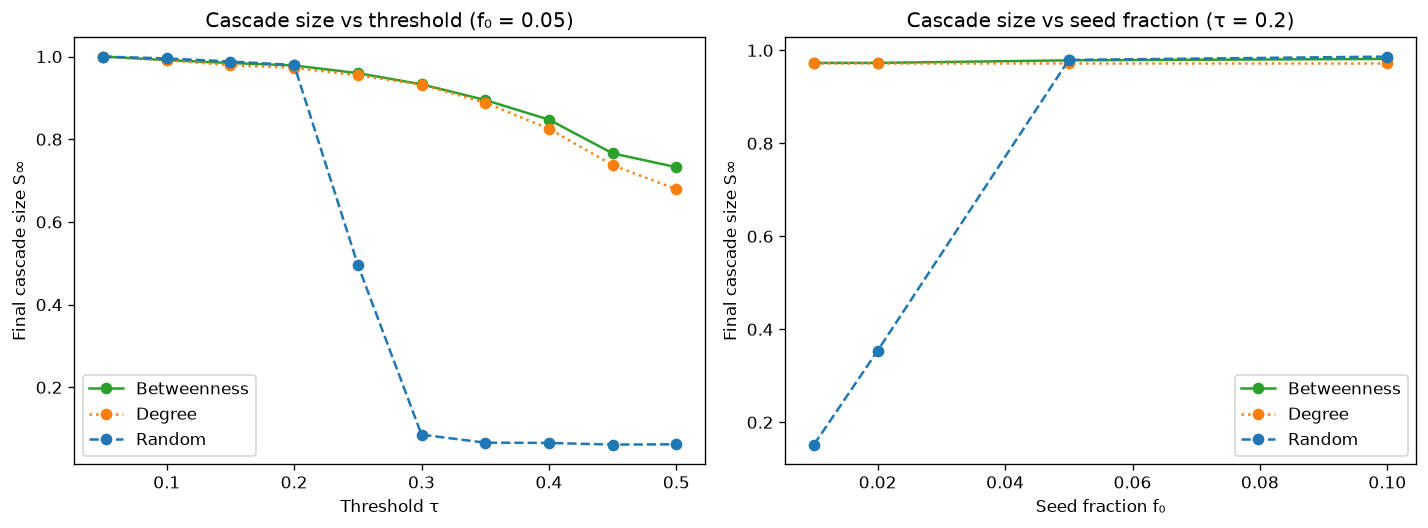

In [170]:
# Plots for both sweeps, with fixed linestyle per strategy
STRAT_STYLES = {
    "Random":      {"linestyle": "--"},
    "Degree":      {"linestyle": ":"},
    "Betweenness": {"linestyle": "-"},
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for strat, group in df_tau.groupby("Strategy"):
    means = group.groupby("tau")["FinalAdoption"].mean()
    axes[0].plot(means.index, means.values, marker="o", label=strat,
                 color=f"C{list(STRAT_STYLES).index(strat)}", **STRAT_STYLES[strat])
axes[0].set_xlabel("Threshold τ")
axes[0].set_ylabel("Final cascade size S∞")
axes[0].set_title(f"Cascade size vs threshold (f₀ = {F0_MAIN})")
axes[0].legend()

for strat, group in df_f0.groupby("Strategy"):
    means = group.groupby("f0")["FinalAdoption"].mean()
    axes[1].plot(means.index, means.values, marker="o", label=strat,
                 color=f"C{list(STRAT_STYLES).index(strat)}", **STRAT_STYLES[strat])
axes[1].set_xlabel("Seed fraction f₀")
axes[1].set_ylabel("Final cascade size S∞")
axes[1].set_title(f"Cascade size vs seed fraction (τ = {TAU_MAIN})")
axes[1].legend()

plt.tight_layout()
plt.show()

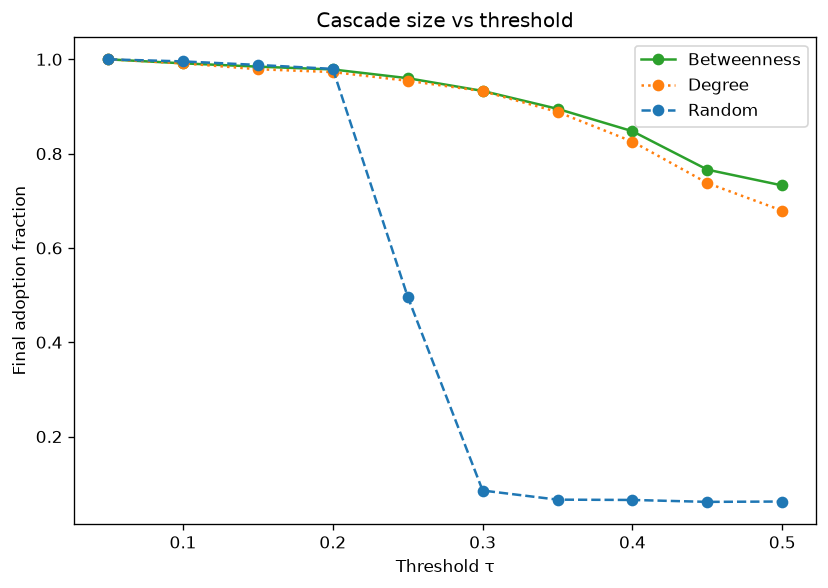

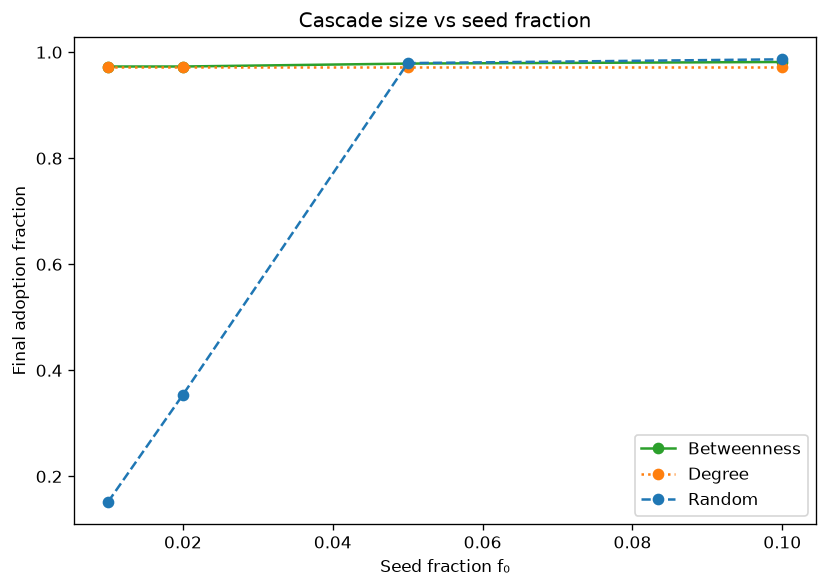

In [171]:
plt.figure(figsize=(7,5))

for strategy, group in df_tau.groupby("Strategy"):

    means = group.groupby("tau")["FinalAdoption"].mean()

    plt.plot(
        means.index,
        means.values,
        marker="o",
        label=strategy,
        color=f"C{list(STRAT_STYLES).index(strategy)}",
        **STRAT_STYLES[strategy]
    )

plt.xlabel("Threshold τ")
plt.ylabel("Final adoption fraction")
plt.title("Cascade size vs threshold")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))

for strategy, group in df_f0.groupby("Strategy"):

    means = group.groupby("f0")["FinalAdoption"].mean()

    plt.plot(
        means.index,
        means.values,
        marker="o",
        label=strategy,
        color=f"C{list(STRAT_STYLES).index(strategy)}",
        **STRAT_STYLES[strategy]
    )

plt.xlabel("Seed fraction f₀")
plt.ylabel("Final adoption fraction")
plt.title("Cascade size vs seed fraction")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Visual plots

Based on 'Visualizing Structural Degradation' in Network_Robustness_Experiment.ipynb

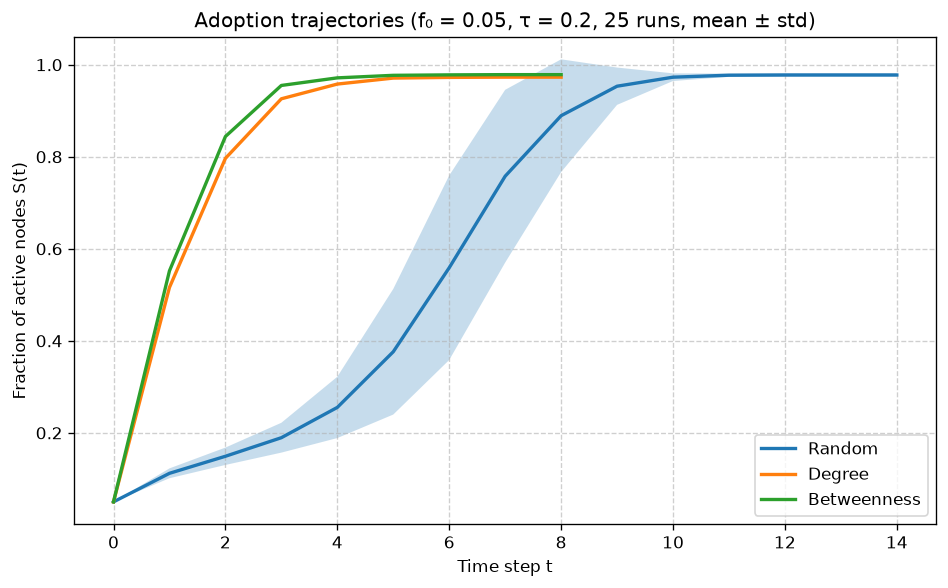

In [172]:
# Monte Carlo averaged adoption trajectories at f0 = F0_MAIN, tau = TAU_MAIN
thresholds = {n: float(TAU_MAIN) for n in G}
strategies = {
    'Random': lambda: random_seeds(G, B_MAIN),
    'Degree': lambda: high_degree_seeds(G, B_MAIN),
    'Betweenness': lambda: betweenness_seeds(G, B_MAIN, bc=BC),
}

plt.figure(figsize=(8, 5))
for strat, seed_fn in strategies.items():
    histories = []
    for run in range(RUNS_PER_SETTING):
        seeds = seed_fn()
        adopted, history = threshold_dynamics(G, seeds, thresholds, max_steps=MAX_STEPS)
        histories.append(history)

    max_len = max(len(h) for h in histories)
    padded = np.array([np.pad(h, (0, max_len - len(h)), mode="edge") for h in histories])

    mean_history = padded.mean(axis=0)
    std_history = padded.std(axis=0)

    plt.plot(range(max_len), mean_history, lw=2, label=strat)
    plt.fill_between(range(max_len),
                     mean_history - std_history,
                     mean_history + std_history,
                     alpha=0.25)

plt.xlabel("Time step t")
plt.ylabel("Fraction of active nodes S(t)")
plt.title(f"Adoption trajectories (f₀ = {F0_MAIN}, τ = {TAU_MAIN}, "
          f"{RUNS_PER_SETTING} runs, mean ± std)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## 14. Visual Comparison (boxplots)

<Figure size 840x480 with 0 Axes>

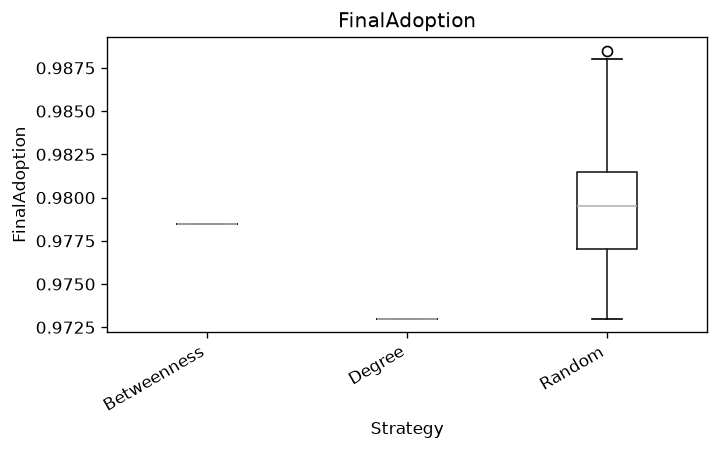

<Figure size 840x480 with 0 Axes>

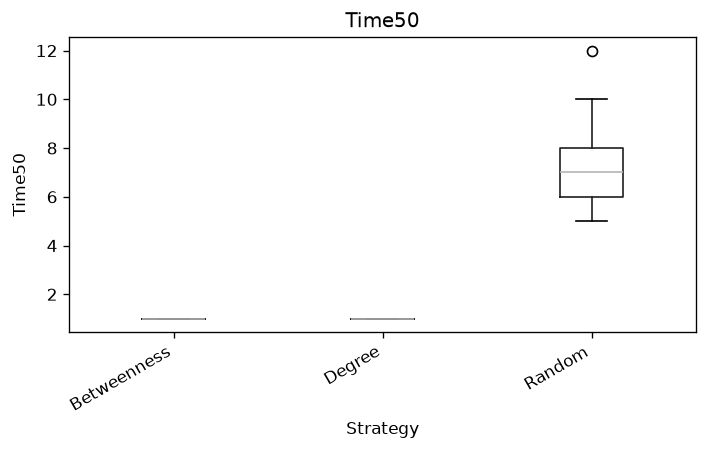

<Figure size 840x480 with 0 Axes>

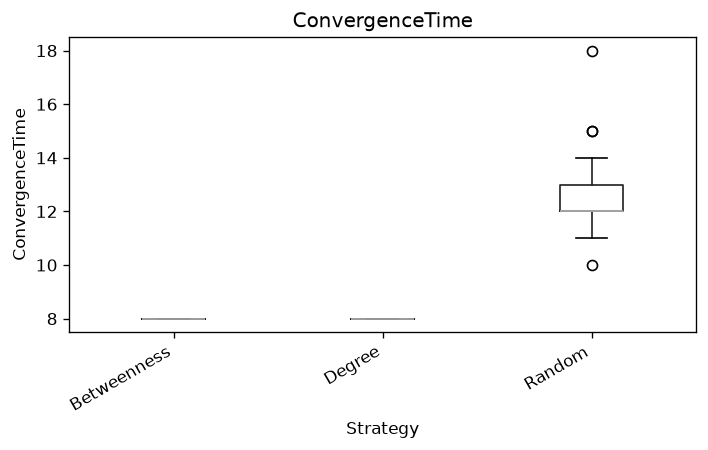

In [173]:
# Boxplots per metric
metrics = ['FinalAdoption', 'Time50', 'ConvergenceTime']
for metric in metrics:
    plt.figure(figsize=(7, 4))
    df_results.boxplot(column=metric, by='Strategy', grid=False)
    plt.title(metric)
    plt.suptitle("")
    plt.xlabel("Strategy")
    plt.ylabel(metric)
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

<Figure size 840x480 with 0 Axes>

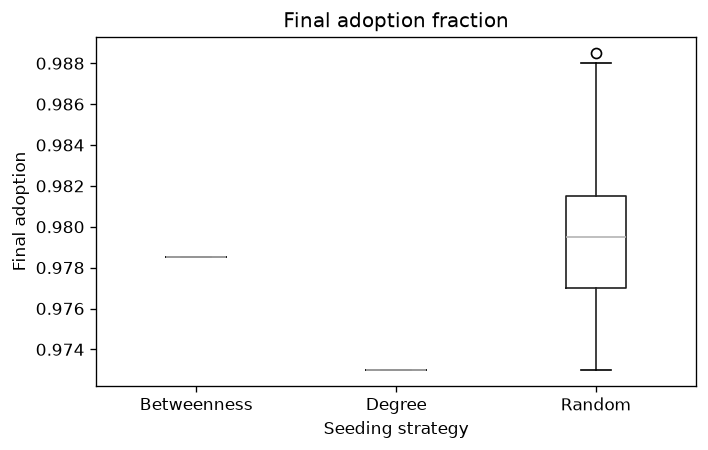

<Figure size 840x480 with 0 Axes>

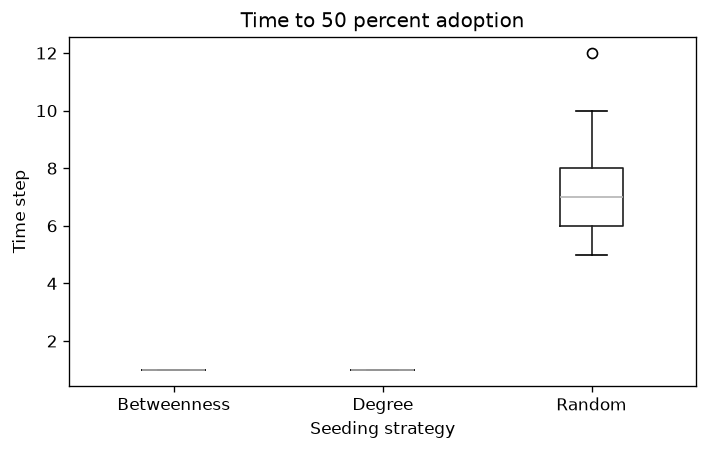

In [174]:
plt.figure(figsize=(7,4))

df_results.boxplot(
    column='FinalAdoption',
    by='Strategy',
    grid=False
)

plt.title("Final adoption fraction")
plt.suptitle("")
plt.xlabel("Seeding strategy")
plt.ylabel("Final adoption")

plt.tight_layout()
plt.show()


plt.figure(figsize=(7,4))

df_results.boxplot(
    column='Time50',
    by='Strategy',
    grid=False
)

plt.title("Time to 50 percent adoption")
plt.suptitle("")
plt.xlabel("Seeding strategy")
plt.ylabel("Time step")

plt.tight_layout()
plt.show()